In [14]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce


In [15]:
df_customers = pd.read_csv("/kaggle/input/brazilian-ecommerce/olist_customers_dataset.csv")
df_orders = pd.read_csv("/kaggle/input/brazilian-ecommerce/olist_orders_dataset.csv")
df_order_items = pd.read_csv("/kaggle/input/brazilian-ecommerce/olist_order_items_dataset.csv")
df_order_reviews = pd.read_csv("/kaggle/input/brazilian-ecommerce/olist_order_reviews_dataset.csv")
df_products = pd.read_csv("/kaggle/input/brazilian-ecommerce/olist_products_dataset.csv")
df_category_name_translation = pd.read_csv("/kaggle/input/brazilian-ecommerce/product_category_name_translation.csv")

In [16]:
df_category_name_translation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [17]:
df_order_reviews.nunique()

,0
review_id,98410
order_id,98673
review_score,5
review_comment_title,4527
review_comment_message,36159
review_creation_date,636
review_answer_timestamp,98248


In [18]:
df_order_reviews["order_id"].duplicated().sum()

np.int64(551)

In [19]:
df_orders["order_id"].duplicated().sum()

np.int64(0)

In [20]:
df_products["product_id"].duplicated().sum()

np.int64(0)

In [21]:
df_order_items["order_item_id"].value_counts().sort_index()

,count
order_item_id,
1,98666
2,9803
3,2287
4,965
5,460
6,256
7,58
8,36
9,28


In [22]:
df_order_items[df_order_items["order_id"] == "0008288aa423d2a3f00fcb17cd7d8719"]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
13,0008288aa423d2a3f00fcb17cd7d8719,1,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.9,13.37
14,0008288aa423d2a3f00fcb17cd7d8719,2,368c6c730842d78016ad823897a372db,1f50f920176fa81dab994f9023523100,2018-02-21 02:55:52,49.9,13.37


In [23]:
df_order_items.groupby("order_id").size().describe()

,0
count,98666.000000
mean,1.141731
std,0.538452
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,21.000000


In [24]:
df_orders[df_orders["order_delivered_customer_date"].isna()]["order_status"].value_counts()

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


In [25]:
#Sales KPIs
total_revenue = df_order_items["price"].sum()
total_freight = df_order_items["freight_value"].sum()
total_orders = df_order_items["order_id"].nunique()
total_products = df_order_items["product_id"].nunique()

print("Revenue:", total_revenue)
print("Freight:", total_freight)
print("Orders:", total_orders)
print("Products:", total_products)
print("Average order value:", total_revenue / total_orders)

Revenue: 13591643.700000003
Freight: 2251909.54
Orders: 98666
Products: 32951
Average order value: 137.7540763788945


In [28]:
#Revenue over time
df_orders["order_purchase_timestamp"] = pd.to_datetime(
    df_orders["order_purchase_timestamp"]
)

sales = df_order_items.merge(
    df_orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

sales["month"] = sales["order_purchase_timestamp"].dt.to_period("M").astype(str)

In [29]:
#Month revenue
monthly_sales = (
    sales.groupby("month")
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_sales.head()

,month,revenue,orders
0,2016-09,267.36,3
1,2016-10,49507.66,308
2,2016-12,10.90,1
3,2017-01,120312.87,789
4,2017-02,247303.02,1733


In [31]:
monthly_sales

,month,revenue,orders
0,2016-09,267.36,3
1,2016-10,49507.66,308
2,2016-12,10.90,1
3,2017-01,120312.87,789
4,2017-02,247303.02,1733
5,2017-03,374344.30,2641
6,2017-04,359927.23,2391
7,2017-05,506071.14,3660
8,2017-06,433038.60,3217
9,2017-07,498031.48,3969


<Axes: title={'center': 'Monthly Revenue'}, xlabel='month'>

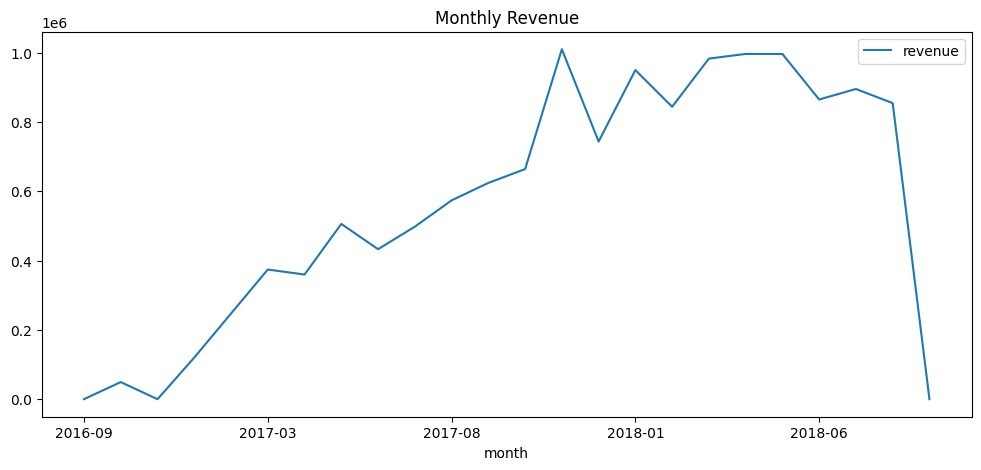

In [30]:
monthly_sales.plot(
    x="month",
    y="revenue",
    figsize=(12, 5),
    title="Monthly Revenue"
)

In [32]:
#Best selling categories
product_sales = (
    df_order_items
    .merge(df_products, on="product_id", how="left")
    .merge(
        df_category_name_translation,
        on="product_category_name",
        how="left"
    )
)

In [33]:
category_sales = (
    product_sales
    .groupby("product_category_name_english")
    .agg(
        revenue=("price", "sum"),
        items_sold=("order_item_id", "count"),
        orders=("order_id", "nunique")
    )
    .sort_values("revenue", ascending=False)
    .reset_index()
)

In [34]:
category_sales.head(10)

,product_category_name_english,revenue,items_sold,orders
0,health_beauty,1258681.34,9670,8836
1,watches_gifts,1205005.68,5991,5624
2,bed_bath_table,1036988.68,11115,9417
3,sports_leisure,988048.97,8641,7720
4,computers_accessories,911954.32,7827,6689
5,furniture_decor,729762.49,8334,6449
6,cool_stuff,635290.85,3796,3632
7,housewares,632248.66,6964,5884
8,auto,592720.11,4235,3897
9,garden_tools,485256.46,4347,3518


In [37]:
# Delivery results
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    df_orders[col] = pd.to_datetime(df_orders[col])

In [38]:
# we'll do the analysis only with delivered orders
delivered = df_orders[
    df_orders["order_status"] == "delivered"
].copy()

In [39]:
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.days

In [40]:
delivered["late_delivery"] = (
    delivered["order_delivered_customer_date"]
    > delivered["order_estimated_delivery_date"]
)

In [41]:
print("Average delivery days:", delivered["delivery_days"].mean())

Average delivery days: 12.093604229294082


In [43]:
print(delivered["late_delivery"].value_counts(normalize=True).mul(100))

late_delivery
False    91.888306
True      8.111694
Name: proportion, dtype: float64


In [45]:
# Merging with reviews
delivery_reviews = delivered.merge(
    df_order_reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

In [47]:
delivery_reviews.groupby("late_delivery")["review_score"].agg(
    ["mean", "count"]
)
#Lower mean review score for late deliveries

,mean,count
late_delivery,,
False,4.293737,88661
True,2.566494,7700
